# Differential expression analysis


You have run the nf-core/rnaseq pipeline and checked the first quality control metrics of your fastq files. This was, however, only the primary analysis and we want to take it further.

Due to the computational demand of the pipeline, you only ran the pipeline on two of the 16 samples in the study yesterday. We provide you an essential output of nf-core/rnaseq pipeline in the `data` folder: It contains the combined epression matrix as produced by Salmon, which provides transcript levels for each gene (rows) and each sample (columns).


We would now like to understand exactly the difference between the expression in our groups of mice. 
Which pipeline would you use for this?

differentialabundance pipeline 

Have a close look at the pipeline's "Usage" page on the [nf-core docs](nf-co.re). You will need to create a samplesheet (based on the column names in the provided matrix).

In [4]:
import os
os.environ["PATH"] += os.pathsep + "/Applications/Docker.app/Contents/Resources/bin"
!docker ps

CONTAINER ID   IMAGE     COMMAND   CREATED   STATUS    PORTS     NAMES


In [4]:
import pandas as pd

# Read the expression matrix
df = pd.read_csv("data/salmon.merged.gene_counts.tsv", sep="\t")

# Get sample names (everything after gene_id and gene_name)
samples = df.columns[2:]

# Create samplesheet
samplesheet = pd.DataFrame({
    "sample": samples,
    "condition": ["_".join(s.split("_")[:2]) for s in samples]
})

# Save it
samplesheet.to_csv("samplesheet.csv", index=False)

print(samplesheet)

        sample condition
0   Sham_oxy_1  Sham_oxy
1   Sham_oxy_2  Sham_oxy
2   Sham_oxy_3  Sham_oxy
3   Sham_oxy_4  Sham_oxy
4   Sham_Sal_1  Sham_Sal
5   Sham_Sal_2  Sham_Sal
6   Sham_Sal_3  Sham_Sal
7   Sham_Sal_4  Sham_Sal
8    SNI_oxy_1   SNI_oxy
9    SNI_oxy_2   SNI_oxy
10   SNI_oxy_3   SNI_oxy
11   SNI_oxy_4   SNI_oxy
12   SNI_Sal_1   SNI_Sal
13   SNI_Sal_2   SNI_Sal
14   SNI_Sal_3   SNI_Sal
15   SNI_Sal_4   SNI_Sal


Please paste here the command you used. You may need to inspect the provided expression matrix more closely and create additional files, like a samplesheet (based on the column names) or a contrast file (there happens to also be one in `data/` that you can use).

Explain all the parameters you set and why you set them in this way. If you used or created additional files as input, explain what they are used for.

Parameter	----Purpose
-profile rnaseq,docker	---Uses the RNA-seq analysis configuration and Docker containers
--input samplesheet.csv	---Provides sample names and their conditions
--contrasts data/contrasts.csv	---Defines which conditions are compared
--matrix ...gene_counts.tsv	---Input gene-level count matrix
--feature_length_matrix ...gene_lengths_Sham_SNI.tsv	---Provides matching gene-length information
--outdir results	---Directory for pipeline outputs

Samplesheet:
Maps each sample to its experimental condition

Contrast file:
Defines the statistical comparisons, including the reference and target conditions.

In [ ]:
!nextflow run nf-core/differentialabundance \
    -profile rnaseq,docker \
    --input samplesheet.csv \
    --contrasts data/contrasts.csv \
    --matrix data/salmon.merged.gene_counts.tsv \
    --feature_length_matrix data/salmon.merged.gene_lengths_Sham_SNI.tsv \
    --outdir results


What were the outputs of the pipeline?

The pipeline produces differential-expression tables for each contrast, containing statistics such as log2 fold change, p-value and adjusted p-value, together with QC and visualization outputs such as PCA, MA plots and heatmaps.

In [11]:
import pandas as pd

# Files
count_nac = "data/rnaseq-out-small/star_salmon/salmon.merged.gene_counts.tsv"
count_target = "data/salmon.merged.gene_counts.tsv"
length_nac = "data/salmon.merged.gene_lengths.tsv"

# Read
nac_counts = pd.read_csv(count_nac, sep="\t")
target_counts = pd.read_csv(count_target, sep="\t")
lengths = pd.read_csv(length_nac, sep="\t")

# --------------------------------------------------
# 1. Check that gene IDs/names correspond
# --------------------------------------------------
assert nac_counts[["gene_id", "gene_name"]].equals(
    lengths[["gene_id", "gene_name"]]
), "NAc count and length files do not have matching genes!"

assert nac_counts[["gene_id", "gene_name"]].equals(
    target_counts[["gene_id", "gene_name"]]
), "NAc and target count matrices do not have matching genes!"

# --------------------------------------------------
# 2. Map NAc samples → target samples using
#    their gene-count profiles
# --------------------------------------------------
nac_samples = nac_counts.columns[2:]
target_samples = target_counts.columns[2:]

mapping = {}

for nac_sample in nac_samples:
    correlations = {
        target_sample: nac_counts[nac_sample].corr(
            target_counts[target_sample]
        )
        for target_sample in target_samples
    }

    best_match = max(correlations, key=correlations.get)
    best_corr = correlations[best_match]

    mapping[nac_sample] = best_match

    print(f"{nac_sample:12} → {best_match:12}  r = {best_corr:.6f}")

# --------------------------------------------------
# 3. Make sure mapping is one-to-one
# --------------------------------------------------
assert len(set(mapping.values())) == len(mapping), \
    "Two NAc samples mapped to the same target sample!"

# --------------------------------------------------
# 4. Rename/reorder gene-length columns
# --------------------------------------------------
new_lengths = lengths.rename(columns=mapping)

# Put columns in exactly the same order as target count matrix
new_lengths = new_lengths[
    ["gene_id", "gene_name"] + list(target_samples)
]

# --------------------------------------------------
# 5. Final sanity checks
# --------------------------------------------------
assert list(new_lengths.columns) == list(target_counts.columns)

# --------------------------------------------------
# 6. Save
# --------------------------------------------------
output = "data/salmon.merged.gene_lengths_Sham_SNI.tsv"

new_lengths.to_csv(output, sep="\t", index=False)

print("\nCreated:")
print(output)
print("\nFinal columns:")
print(new_lengths.columns.tolist())

Nac_oxy_1    → Sham_oxy_1    r = 0.999962
Nac_oxy_2    → SNI_oxy_1     r = 0.999914
Nac_oxy_3    → SNI_oxy_2     r = 0.999881
Nac_oxy_4    → Sham_oxy_2    r = 0.999935
Nac_oxy_5    → Sham_oxy_3    r = 0.999995
Nac_oxy_6    → SNI_oxy_3     r = 0.999500
Nac_oxy_7    → SNI_oxy_4     r = 0.999999
Nac_oxy_8    → Sham_oxy_4    r = 0.998157
Nac_Sal_1    → SNI_Sal_1     r = 0.999972
Nac_Sal_2    → Sham_Sal_1    r = 0.999842
Nac_Sal_3    → SNI_Sal_2     r = 1.000000
Nac_Sal_4    → Sham_Sal_2    r = 0.999925
Nac_Sal_5    → SNI_Sal_3     r = 0.999977
Nac_Sal_6    → Sham_Sal_3    r = 0.999999
Nac_Sal_7    → SNI_Sal_4     r = 1.000000
Nac_Sal_8    → Sham_Sal_4    r = 0.999998

Created:
data/salmon.merged.gene_lengths_Sham_SNI.tsv

Final columns:
['gene_id', 'gene_name', 'Sham_oxy_1', 'Sham_oxy_2', 'Sham_oxy_3', 'Sham_oxy_4', 'Sham_Sal_1', 'Sham_Sal_2', 'Sham_Sal_3', 'Sham_Sal_4', 'SNI_oxy_1', 'SNI_oxy_2', 'SNI_oxy_3', 'SNI_oxy_4', 'SNI_Sal_1', 'SNI_Sal_2', 'SNI_Sal_3', 'SNI_Sal_4']


Would you exclude any samples? If yes, which and why?

Samples with clear QC or alignment failures should be excluded before differential-expression analysis because poor-quality samples can introduce noise and distort the estimated expression differences. The strongest outlier was SRX19144491 due to its very low alignment rate.

How many genes were differentially expressed in each contrast? Does this confirm what the paper mentions?

The analysis identified 7 DEGs for Sham_oxy vs Sham_Sal and 17 DEGs for SNI_oxy vs SNI_Sal. These numbers do not directly reproduce the paper's reported DEG numbers because the paper used different statistical and fold-change thresholds and a 2×2 factorial design.

SNI_oxy vs SNI_Sal: 37 DE genes
Sham_oxy vs Sham_Sal: 25 DE genes
using an adjusted p-value threshold of 0.1 and an absolute log2 fold-change threshold of 0.5.

The paper mentions differentially expressed genes in three brain regions : the NAc, mPFC and VTA. Briefly explain what these 3 regions are.

These are three brain regions involved in the reward/addiction circuitry studied in the paper:
- NAc — Nucleus Accumbens: reward, motivation and addiction-related processing.
- mPFC — medial Prefrontal Cortex: cognitive/executive control and regulation of reward-related behaviour.
- VTA — Ventral Tegmental Area: contains many dopamine-producing neurons and sends dopaminergic projections to regions such as the NAc and mPFC.

Is there anyway from the paper and the material and methods for us to know which genes are included in these regions?

Bulk RNA-seq measures all genes in each dissected tissue, so no gene “belongs” to one region. The region is a property of the sample, recorded in GEO and the metadata. The paper lists the DEGs per region in its supplementary tables. Our 16 samples (4 groups × 4) are probably a single region; check the metadata.

Once you have your list of differentially expressed genes, do you think just communicating those to the biologists would be sufficient? What does the publication state?

No, just reporting the differentially expressed genes would not be enough to explain what oxycodone withdrawal or nerve injury is doing biologically.
The publication therefore goes beyond the DEG lists by performing additional analyses to interpret the biological meaning of the changes — including pathway/gene-set analyses and comparisons of the direction and overlap of transcriptional changes.

Please reproduce the Venn Diagram from Figure 3, not taking into account the brain regions but just the contrasts mentionned.

SNI_oxy vs SNI_Sal: 37
Sham_oxy vs Sham_Sal: 25
Overlap: 1


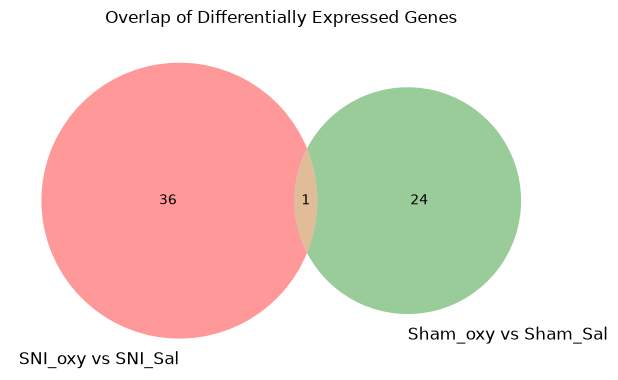

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib_venn import venn2

# Load results
sni = pd.read_csv(
    "results/tables/differential/rnaseq/condition_control_treated_study.deseq2.results.tsv",
    sep="\t"
)

sham = pd.read_csv(
    "results/tables/differential/rnaseq/condition_control_treated_test_study.deseq2.results.tsv",
    sep="\t"
)

# Apply DEG threshold
sni_genes = set(
    sni.loc[
        (sni["padj"] <= 0.1) &
        (sni["log2FoldChange"].abs() >= 0.5),
        "gene_id"
    ].dropna()
)

sham_genes = set(
    sham.loc[
        (sham["padj"] <= 0.1) &
        (sham["log2FoldChange"].abs() >= 0.5),
        "gene_id"
    ].dropna()
)

# Print numbers
print("SNI_oxy vs SNI_Sal:", len(sni_genes))
print("Sham_oxy vs Sham_Sal:", len(sham_genes))
print("Overlap:", len(sni_genes & sham_genes))

# Venn diagram
plt.figure(figsize=(7, 7))

venn2(
    [sni_genes, sham_genes],
    set_labels=[
        "SNI_oxy vs SNI_Sal",
        "Sham_oxy vs Sham_Sal"
    ]
)

plt.title("Overlap of Differentially Expressed Genes")
plt.show()